# PAWS Project 1 — Leakage-controlled 5-fold CV

This notebook replaces **only the experimental training/evaluation section** of `experiments.ipynb`. The exploratory data/tokenizer analysis in the original notebook remains useful, but its globally fitted `encoders` objects must **not** be used for the cross-validation here.

The main evaluation protocol: *train only* is split into five folds using unordered-pair group stratification; each training fold fits a distinct BPE and NGram vocabulary; encoded sparse matrices are reused for every architecture and hyperparameter configuration. The official validation and test are left untouched until final evaluation.

Use the modified modules in `src/` from the companion files. Do not reuse existing `results` or old CV metrics because their preprocessing protocol was different.

In [1]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import torch

from src import experiment, clslib, analysis, bayes_rope
from src.dataset import load_paws, paws_pairs
from src.figures import save_table, save_figure

ROOT = Path("results_strict")
ROOT.mkdir(exist_ok=True)
Path("tables").mkdir(exist_ok=True)
Path("images").mkdir(exist_ok=True)

SEED = 0
NUM_FOLDS = 5
outcome_space = clslib.NamedClasses(["non-paraphrase", "paraphrase"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch device:", DEVICE)

PyTorch device: cpu


## 1. Group-stratified folds

Group by **unordered sentence pair**, not by sentence-connected components. Reversed duplicate pairs cannot cross a training/evaluation boundary. Class proportions are approximately preserved.

In [2]:
dataset = load_paws(remove_conflicts=True)
train_pairs = paws_pairs(dataset["train"])
folds = experiment.cross_validation_split(train_pairs, k=NUM_FOLDS, seed=SEED)
fold_report = experiment.fold_diagnostics(folds)
display(fold_report)
assert (fold_report["overlapping_pairs"] == 0).all()
assert (fold_report["validation"] > 0).all()
fold_report.to_csv(ROOT / "fold_diagnostics.csv", index=False)

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338


,fold,train,validation,label0,label1,label1_ratio,overlapping_pairs,validation_pairs_with_shared_sentence
0,0,39470,9868,5508,4360,0.441832,0,9418
1,1,39470,9868,5508,4360,0.441832,0,9474
2,2,39470,9868,5509,4359,0.441731,0,9436
3,3,39471,9867,5508,4359,0.441776,0,9442
4,4,39471,9867,5508,4359,0.441776,0,9390


## 2. Fit BPE + NGram once per *training fold* and cache features

The third representation is **BPE unigram+bigram counts**, pre-specified independently of the previous label-informed 5-gram Jaccard exploratory analysis. Every classifier shares the same matrices in each fold.

This cell is the only one that trains BPE. On subsequent executions the feature matrices are loaded from disk. If you change the tokenizer/representation settings, use a new cache directory or remove the old cache.

In [3]:
prepared = experiment.prepare_cv_features(
    folds,
    cache_dir=ROOT / "feature_cache_bpe8000_ngram12_diff",
    vocab_size=8000,
    min_frequency=2,
    ngram_n=2,
    ngram_include_lower=True,
    ngram_min_count=5,
    ngram_max_features=8000,
    pair_mode="diff",
)
print("Prepared representations:", list(prepared[0]))
print("First fold, BagOfWords shape:", prepared[0]["BagOfWords"]["X_train"].shape)

Prepare CV features:   0%|          | 0/5 [00:00<?, ?it/s]

Fold 0: train BPE only on 39,470 training pairs



  TokenIndicator: X_train=(39470, 16000), X_val=(9868, 16000)
  BagOfWords: X_train=(39470, 16000), X_val=(9868, 16000)
  NGram: X_train=(39470, 16000), X_val=(9868, 16000)
Fold 1: train BPE only on 39,470 training pairs



  TokenIndicator: X_train=(39470, 16000), X_val=(9868, 16000)
  BagOfWords: X_train=(39470, 16000), X_val=(9868, 16000)
  NGram: X_train=(39470, 16000), X_val=(9868, 16000)
Fold 2: train BPE only on 39,470 training pairs



  TokenIndicator: X_train=(39470, 16000), X_val=(9868, 16000)
  BagOfWords: X_train=(39470, 16000), X_val=(9868, 16000)
  NGram: X_train=(39470, 16000), X_val=(9868, 16000)
Fold 3: train BPE only on 39,471 training pairs



  TokenIndicator: X_train=(39471, 16000), X_val=(9867, 16000)
  BagOfWords: X_train=(39471, 16000), X_val=(9867, 16000)
  NGram: X_train=(39471, 16000), X_val=(9867, 16000)
Fold 4: train BPE only on 39,471 training pairs



  TokenIndicator: X_train=(39471, 16000), X_val=(9867

## 3. Logistic Regression and Linear SVM

Separate grids for both linear models. Logistic uses `liblinear` and an increased iteration limit; convergence warnings are **not** suppressed. Scores and fitted models are saved after each completed configuration for safe resumption.

In [4]:
linear_specs = [
    {
        "family": "logistic", "model_option": "logistic",
        "representations": list(experiment.REPRESENTATIONS),
        "base_args": {"max_iter": 2000},
        "grid": {"C": [0.01, 0.1, 1.0, 10.0]},
    },
    {
        "family": "svm", "model_option": "svm",
        "representations": list(experiment.REPRESENTATIONS),
        "base_args": {"max_iter": 5000},
        "grid": {"C": [0.01, 0.1, 1.0, 10.0]},
    },
]
linear_results, linear_leaderboard = experiment.run_grid_search(
    folds, outcome_space, prepared, linear_specs,
    results_dir=ROOT / "models",
    save_summary_to=ROOT / "linear_leaderboard.csv",
)
display(linear_leaderboard.head(15))

logistic/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

logistic/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

logistic/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

logistic/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

logistic/BagOfWords:   0%|          | 0/5 [00:00<?, ?it/s]

logistic/BagOfWords:   0%|          | 0/5 [00:00<?, ?it/s]

... (15 outputs left out)

svm/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

svm/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

svm/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

,model,family,representation,params,mean_accuracy,std_accuracy,mean_macro_f1
0,logistic_TokenIndicator_C0.01,logistic,TokenIndicator,"{""C"": 0.01}",0.572054,0.002818,0.496969
8,logistic_NGram_C0.01,logistic,NGram,"{""C"": 0.01}",0.571770,0.004208,0.511020
4,logistic_BagOfWords_C0.01,logistic,BagOfWords,"{""C"": 0.01}",0.562649,0.003714,0.493801
20,svm_NGram_C0.01,svm,NGram,"{""C"": 0.01}",0.544347,0.003062,0.514146
9,logistic_NGram_C0.1,logistic,NGram,"{""C"": 0.1}",0.542705,0.002610,0.514891
21,svm_NGram_C0.1,svm,NGram,"{""C"": 0.1}",0.530524,0.004301,0.515879
10,logistic_NGram_C1.0,logistic,NGram,"{""C"": 1.0}",0.530463,0.003765,0.516534
12,svm_TokenIndicator_C0.01,svm,TokenIndicator,"{""C"": 0.01}",0.518505,0.003427,0.474435
22,svm_NGram_C1.0,svm,NGram,"{""C"": 1.0}",0.517431,0.006006,0.507614
11,logistic_NGram_C10.0,logistic,NGram,"{""C"": 10.0}",0.516417,0.005826,0.506813


## 4. Shallow MLP tuning

Early-stopping epoch selection uses an **inner group-aware validation split**. A new model is refitted using the full outer training fold for the selected number of epochs. The held-out outer fold is evaluated **only once**.

The following small grid explores hidden size and dropout. Learning rate is kept fixed for the initial experiment to control computational cost.

In [5]:
mlp_specs = [
    {
        "family": "mlp", "model_option": "mlp",
        "representations": list(experiment.REPRESENTATIONS),
        "base_args": {
            "num_hidden_layers": 1,
            "activation": "relu",
            "batch_size": 64,
            "learning_rate": 1e-4,
            "weight_decay": 1e-4,
            "num_epochs": 20,
            "patience": 2,
            "seed": SEED,
            "device": DEVICE,
        },
        "grid": {"hidden_dim": [64, 128], "dropout": [0.1, 0.3]},
    },
]
mlp_results, mlp_leaderboard = experiment.run_grid_search(
    folds, outcome_space, prepared, mlp_specs,
    results_dir=ROOT / "models",
    save_summary_to=ROOT / "mlp_leaderboard.csv",
)
display(mlp_leaderboard.head(15))

mlp/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

/Users/abrilrisso/Desktop/master/NLP1/nlp_project1/nlp1/src/smlp.py:85: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5657
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5715
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5702
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5691
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5799


mlp/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5816
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5801
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5800
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5810
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5794


mlp/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

... (16 outputs left out)

MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5874
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5823
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5930
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5801
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5816


mlp/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5680
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5842
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5874
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5832
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5771


,model,family,representation,params,mean_accuracy,std_accuracy,mean_macro_f1
10,mlp_NGram_dropout0.3_hidden_dim64,mlp,NGram,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.584884,0.005302,0.487311
9,mlp_NGram_dropout0.1_hidden_dim128,mlp,NGram,"{""dropout"": 0.1, ""hidden_dim"": 128}",0.584215,0.008294,0.483909
5,mlp_BagOfWords_dropout0.1_hidden_dim128,mlp,BagOfWords,"{""dropout"": 0.1, ""hidden_dim"": 128}",0.583769,0.002375,0.461927
8,mlp_NGram_dropout0.1_hidden_dim64,mlp,NGram,"{""dropout"": 0.1, ""hidden_dim"": 64}",0.582533,0.004059,0.476824
7,mlp_BagOfWords_dropout0.3_hidden_dim128,mlp,BagOfWords,"{""dropout"": 0.3, ""hidden_dim"": 128}",0.582087,0.002121,0.456122
1,mlp_TokenIndicator_dropout0.1_hidden_dim128,mlp,TokenIndicator,"{""dropout"": 0.1, ""hidden_dim"": 128}",0.580405,0.000878,0.422951
11,mlp_NGram_dropout0.3_hidden_dim128,mlp,NGram,"{""dropout"": 0.3, ""hidden_dim"": 128}",0.579959,0.007655,0.484285
4,mlp_BagOfWords_dropout0.1_hidden_dim64,mlp,BagOfWords,"{""dropout"": 0.1, ""hidden_dim"": 64}",0.577709,0.001344,0.435385
3,mlp_TokenIndicator_dropout0.3_hidden_dim128,mlp,TokenIndicator,"{""dropout"": 0.3, ""hidden_dim"": 128}",0.576371,0.000551,0.409974
6,mlp_BagOfWords_dropout0.3_hidden_dim64,mlp,BagOfWords,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.575175,0.001440,0.428587


## 5. Third architecture: deeper MLP

The tutorial's one-hidden-layer MLP is compared with a two-hidden-layer MLP, keeping the other training choices fixed. This fulfils the third-architecture requirement independently of SVM (which is an additional architecture).

In [6]:
deep_specs = [
    {
        "family": "mlp_deep", "model_option": "mlp",
        "representations": list(experiment.REPRESENTATIONS),
        "base_args": {
            "num_hidden_layers": 2,
            "activation": "relu",
            "batch_size": 64,
            "learning_rate": 1e-4,
            "weight_decay": 1e-4,
            "num_epochs": 20,
            "patience": 2,
            "seed": SEED,
            "device": DEVICE,
        },
        "grid": {"hidden_dim": [128], "dropout": [0.1]},
    },
]
deep_results, deep_leaderboard = experiment.run_grid_search(
    folds, outcome_space, prepared, deep_specs,
    results_dir=ROOT / "models",
    save_summary_to=ROOT / "deep_leaderboard.csv",
)
display(deep_leaderboard)

mlp/TokenIndicator:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5701
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5584
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5641
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5599
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5856


mlp/BagOfWords:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5701
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5706
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5702
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5707
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5714


mlp/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5572
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5784
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5811
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5801
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5804


,model,family,representation,params,mean_accuracy,std_accuracy,mean_macro_f1
2,mlp_deep_NGram_dropout0.1_hidden_dim128,mlp_deep,NGram,"{""dropout"": 0.1, ""hidden_dim"": 128}",0.575439,0.010268,0.455130
1,mlp_deep_BagOfWords_dropout0.1_hidden_dim128,mlp_deep,BagOfWords,"{""dropout"": 0.1, ""hidden_dim"": 128}",0.570615,0.000503,0.416660
0,mlp_deep_TokenIndicator_dropout0.1_hidden_dim128,mlp_deep,TokenIndicator,"{""dropout"": 0.1, ""hidden_dim"": 128}",0.567636,0.011018,0.412941


## 6. Reload all completed CV configurations

Execute even after a kernel restart. Partial configurations lacking their `cv.pkl` are not treated as finished.

In [7]:
all_results = {}
config_map = {}
for p in sorted((ROOT / "models").glob("*/cv.pkl")):
    with p.open("rb") as f:
        all_results[p.parent.name] = [pickle.load(f)]
    import json
    config_map[p.parent.name] = json.loads((p.parent / "config.json").read_text())
print("Complete model configurations:", len(all_results))
assert all_results, "Train at least one configuration first"

cv_df = analysis.make_data_frame(all_results)
wide = bayes_rope.scores_by_model(cv_df, fold_col="fold")
assert len(wide) == NUM_FOLDS

# Majority class must be determined using TRAIN labels, not validation labels.
majority = {}
for f, split in folds.items():
    train_labels = np.asarray([y for _, y in split["training"]], dtype=int)
    heldout_labels = np.asarray([y for _, y in split["validation"]], dtype=int)
    majority_label = int(np.bincount(train_labels).argmax())
    majority[(0, f)] = np.mean(heldout_labels == majority_label)
wide["majority_class"] = [majority[index] for index in wide.index]
summary = wide.agg(["mean", "std"]).T.sort_values("mean", ascending=False)
display(summary)
save_table(summary, ROOT / "cv_summary.csv")

Complete model configurations: 39


,mean,std
model,,
mlp_NGram_dropout0.3_hidden_dim64,0.584884,0.005302
mlp_NGram_dropout0.1_hidden_dim128,0.584215,0.008294
mlp_BagOfWords_dropout0.1_hidden_dim128,0.583769,0.002375
mlp_NGram_dropout0.1_hidden_dim64,0.582533,0.004059
mlp_BagOfWords_dropout0.3_hidden_dim128,0.582087,0.002121
mlp_TokenIndicator_dropout0.1_hidden_dim128,0.580405,0.000878
mlp_NGram_dropout0.3_hidden_dim128,0.579959,0.007655
mlp_BagOfWords_dropout0.1_hidden_dim64,0.577709,0.001344
mlp_TokenIndicator_dropout0.3_hidden_dim128,0.576371,0.000551


,mean,std
model,,
mlp_NGram_dropout0.3_hidden_dim64,0.584884,0.005302
mlp_NGram_dropout0.1_hidden_dim128,0.584215,0.008294
mlp_BagOfWords_dropout0.1_hidden_dim128,0.583769,0.002375
mlp_NGram_dropout0.1_hidden_dim64,0.582533,0.004059
mlp_BagOfWords_dropout0.3_hidden_dim128,0.582087,0.002121
mlp_TokenIndicator_dropout0.1_hidden_dim128,0.580405,0.000878
mlp_NGram_dropout0.3_hidden_dim128,0.579959,0.007655
mlp_BagOfWords_dropout0.1_hidden_dim64,0.577709,0.001344
mlp_TokenIndicator_dropout0.3_hidden_dim128,0.576371,0.000551


## 7. Bayesian correlated t-test with ROPE

ROPE = ±0.01 accuracy (±1 percentage point) is a chosen *practical* threshold, not something dictated by the dataset. Scores are **paired** by `(run, fold)`. A small number of selected, interpretable comparisons is preferred over every possible hyperparameter pair.

**Selection caveat:** choosing the best model using the very same 5 folds produces optimistic selected CV scores and can bias posterior comparisons. Treat comparisons of selected winners as exploratory. The untouched official validation/test provide independent checks after the decision is locked.

Best configuration per family: {'logistic': 'logistic_TokenIndicator_C0.01', 'svm': 'svm_NGram_C0.01', 'mlp': 'mlp_NGram_dropout0.3_hidden_dim64', 'mlp_deep': 'mlp_deep_NGram_dropout0.1_hidden_dim128'}


,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,logistic_TokenIndicator_C0.01,svm_NGram_C0.01,0.027707,0.023901,0.031512,0.999896,0.000098,0.000005,logistic_TokenIndicator_C0.01 better
1,logistic_TokenIndicator_C0.01,mlp_NGram_dropout0.3_hidden_dim64,-0.012830,-0.020944,-0.004716,0.000725,0.193136,0.806140,undecided
2,logistic_TokenIndicator_C0.01,mlp_deep_NGram_dropout0.1_hidden_dim128,-0.003385,-0.027347,0.020577,0.097931,0.659003,0.243066,undecided
3,logistic_TokenIndicator_C0.01,majority_class,0.013843,0.008568,0.019118,0.943436,0.056448,0.000116,undecided
4,svm_NGram_C0.01,mlp_NGram_dropout0.3_hidden_dim64,-0.040537,-0.047137,-0.033936,0.000014,0.000091,0.999894,mlp_NGram_dropout0.3_hidden_dim64 better
5,svm_NGram_C0.01,mlp_deep_NGram_dropout0.1_hidden_dim128,-0.031092,-0.053474,-0.008710,0.003498,0.026013,0.970490,undecided
6,svm_NGram_C0.01,majority_class,-0.013864,-0.019575,-0.008152,0.000158,0.066618,0.933224,undecided
7,mlp_NGram_dropout0.3_hidden_dim64,mlp_deep_NGram_dropout0.1_hidden_dim128,0.009445,-0.013841,0.032730,0.475193,0.484170,0.040637,undecided
8,mlp_NGram_dropout0.3_hidden_dim64,majority_class,0.026673,0.016830,0.036516,0.995356,0.004398,0.000246,mlp_NGram_dropout0.3_hidden_dim64 better
9,mlp_deep_NGram_dropout0.1_hidden_dim128,majority_class,0.017228,-0.001844,0.036301,0.823972,0.167715,0.008313,undecided


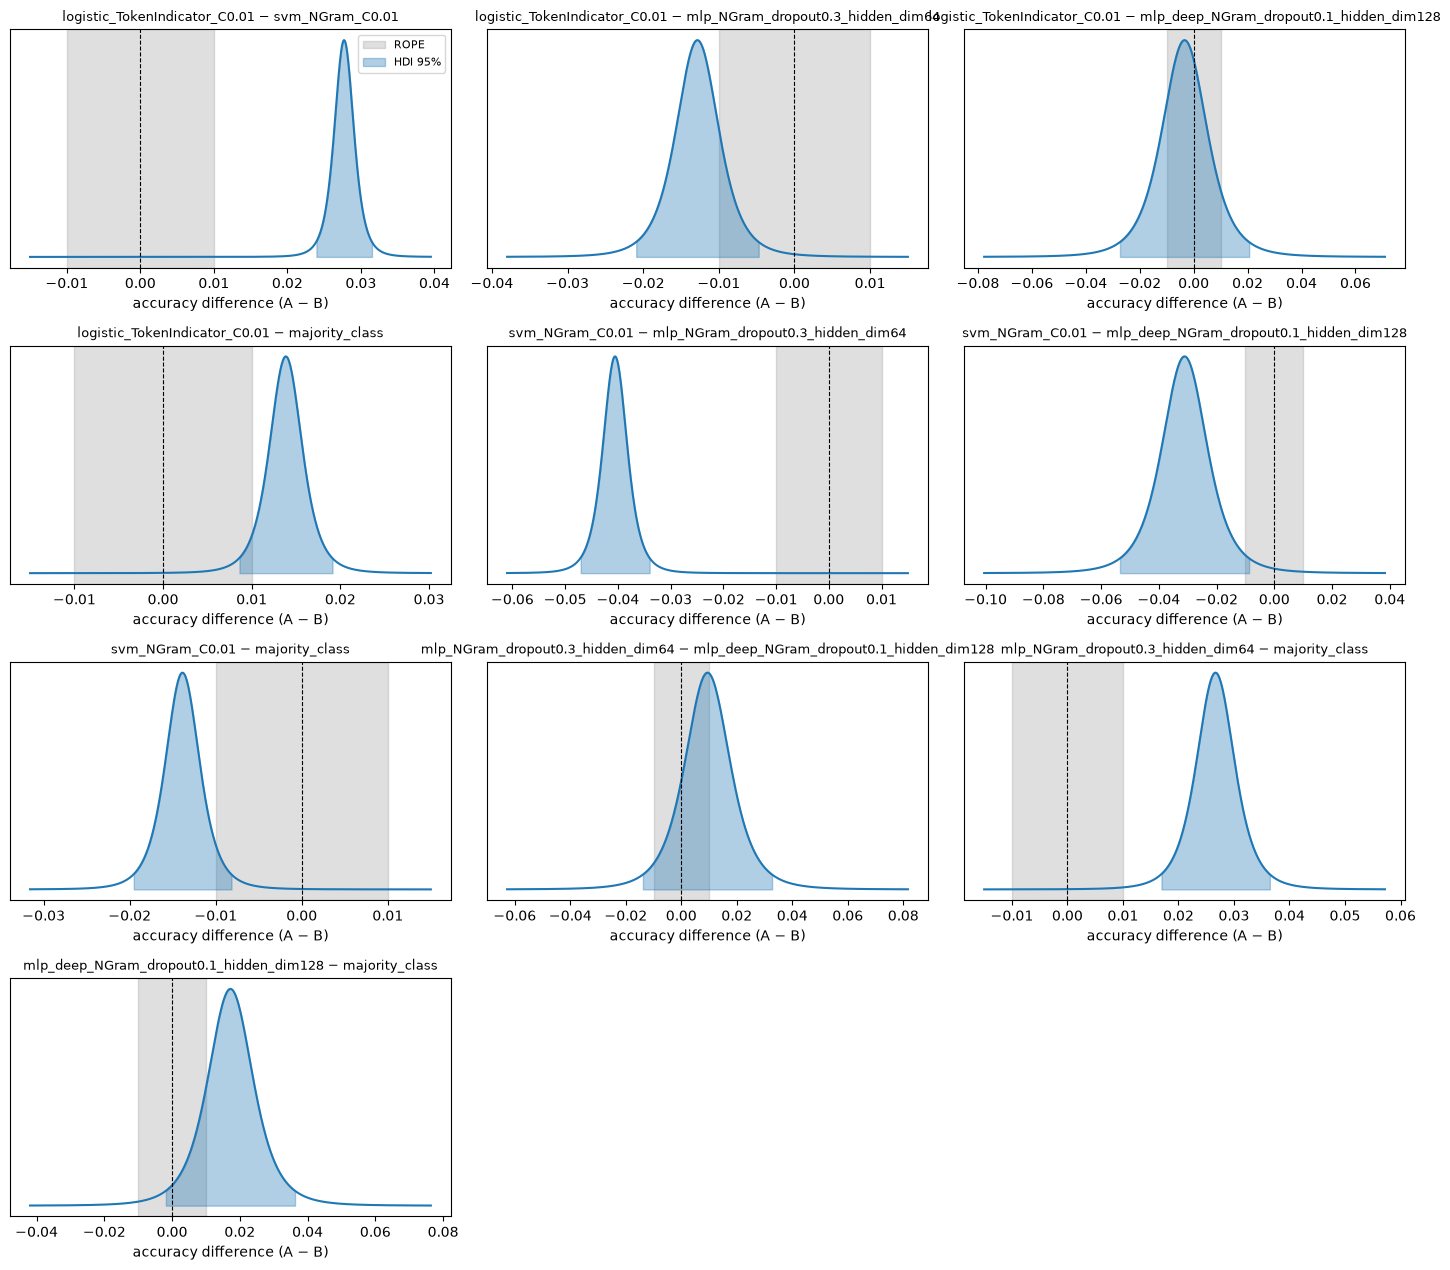

In [8]:
from src.bayes_rope import compare_models, plot_posteriors

ROPE = 0.01
families = ["logistic", "svm", "mlp", "mlp_deep"]
selected = {}
for family in families:
    names = [name for name in wide.columns
             if name != "majority_class" and config_map[name]["model"] == ("mlp" if family.startswith("mlp") else family)
             and name.startswith(family + "_")
             and (family != "mlp" or not name.startswith("mlp_deep_"))]
    if names:
        selected[family] = wide[names].mean().idxmax()
print("Best configuration per family:", selected)

# The majority baseline is included; results are descriptive if CV selects the winners.
models_to_compare = list(dict.fromkeys(selected.values())) + ["majority_class"]
if len(models_to_compare) >= 2:
    comparisons, posteriors = compare_models(wide, k=NUM_FOLDS, rope=ROPE,
                                              models=models_to_compare)
    display(comparisons)
    save_table(comparisons, ROOT / "bayesian_rope.csv")
    fig = plot_posteriors(posteriors, rope=ROPE)
    save_figure(fig, ROOT / "bayesian_rope.png")

## 8. Independent final evaluation — run only after selecting a configuration

The selected configuration must be fixed before evaluating the official test. Fit a **new BPE on the entire official train** and fit NGram there if selected. Use the official validation as an independent check. The test must be evaluated only for the final fixed system.

In [9]:
# Optional final evaluation: uncomment after training and model selection.
# This block deliberately does not evaluate test automatically.
# The selected configuration and its hyperparameters are in:
# config_map[selected["logistic"]]  # or selected["mlp"], selected["svm"]
# If you run a final test, train BPE from scratch on ALL official train,
# rebuild the selected representation, retrain the classifier, and evaluate
# official test once. Do not apply fold-0's fitted encoder to the full train.

In [10]:

import pickle
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

models_to_check = [
    "mlp_NGram_dropout0.3_hidden_dim64",
    "logistic_TokenIndicator_C0.01",
    "logistic_NGram_C1.0",
    "svm_NGram_C0.01",
]

for name in models_to_check:
    path = ROOT / "models" / name / "cv.pkl"

    with open(path, "rb") as f:
        result = pickle.load(f)

    y_true = []
    y_pred = []

    for fold in sorted(result["predictions"]):
        labels = [
            label
            for _, label in folds[fold]["validation"]
        ]

        y_true.extend(labels)
        y_pred.extend(result["predictions"][fold])

    print(f"\n{'=' * 60}")
    print(name)

    print("\nConfusion matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=["non-paraphrase", "paraphrase"],
            digits=4
        )
    )



mlp_NGram_dropout0.3_hidden_dim64

Confusion matrix:
[[25150  2391]
 [18090  3707]]

Classification report:
                precision    recall  f1-score   support

non-paraphrase     0.5816    0.9132    0.7106     27541
    paraphrase     0.6079    0.1701    0.2658     21797

      accuracy                         0.5849     49338
     macro avg     0.5948    0.5416    0.4882     49338
  weighted avg     0.5932    0.5849    0.5141     49338


logistic_TokenIndicator_C0.01

Confusion matrix:
[[23641  3900]
 [17214  4583]]

Classification report:
                precision    recall  f1-score   support

non-paraphrase     0.5787    0.8584    0.6913     27541
    paraphrase     0.5403    0.2103    0.3027     21797

      accuracy                         0.5721     49338
     macro avg     0.5595    0.5343    0.4970     49338
  weighted avg     0.5617    0.5721    0.5196     49338


logistic_NGram_C1.0

Confusion matrix:
[[17269 10272]
 [12894  8903]]

Classification report:
             

In [11]:

from pathlib import Path
from collections import Counter
from tokenizers import Tokenizer
import pickle
import json
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Load the actual tokenizer and NGram vocabulary
# ---------------------------------------------------------

FOLD = 0
CACHE = (
    Path("results_strict")
    / "feature_cache_bpe8000_ngram12_diff"
    / f"fold-{FOLD}"
)

tokenizer = Tokenizer.from_file(str(CACHE / "tokenizer.json"))

with open(CACHE / "ngram_vocab.pkl", "rb") as f:
    vocab = pickle.load(f)

with open(CACHE / "metadata.json") as f:
    metadata = json.load(f)

assert metadata["ngram_n"] == 2
assert metadata["ngram_include_lower"] is True

MIN_COUNT = metadata["ngram_min_count"]

kept = {
    1: {g for g in vocab if len(g) == 1},
    2: {g for g in vocab if len(g) == 2},
}

print("NGram configuration:")
print("  min_count:", MIN_COUNT)
print("  max_features:", metadata["ngram_max_features"])
print("  retained unigrams:", len(kept[1]))
print("  retained bigrams:", len(kept[2]))


# ---------------------------------------------------------
# 2. Helpers
# ---------------------------------------------------------

def get_ngrams(tokens):
    return {
        1: [(t,) for t in tokens],
        2: list(zip(tokens, tokens[1:])),
    }


def iter_tokenized(texts, batch_size=512):
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        for encoding in tokenizer.encode_batch(batch):
            yield encoding.tokens


train_texts = [
    s
    for (s1, s2), _ in folds[FOLD]["training"]
    for s in (s1, s2)
]

val_texts = [
    s
    for (s1, s2), _ in folds[FOLD]["validation"]
    for s in (s1, s2)
]


# ---------------------------------------------------------
# 3. Count ALL n-grams in the training corpus
# ---------------------------------------------------------

counts = {1: Counter(), 2: Counter()}

for tokens in iter_tokenized(train_texts):
    grams = get_ngrams(tokens)
    counts[1].update(grams[1])
    counts[2].update(grams[2])

vocab_stats = []

for n in [1, 2]:
    freq = counts[n]

    total_types = len(freq)
    hapax = sum(c == 1 for c in freq.values())
    frequent = sum(c >= MIN_COUNT for c in freq.values())
    retained = len(kept[n])

    total_occurrences = sum(freq.values())
    retained_occurrences = sum(
        c for gram, c in freq.items()
        if gram in kept[n]
    )

    vocab_stats.append({
        "n": n,
        "unique_types": total_types,
        "hapax_types_%": 100 * hapax / total_types,
        "discarded_by_min_count_%":
            100 * (total_types - frequent) / total_types,
        "retained_types": retained,
        "total_types_discarded_%":
            100 * (1 - retained / total_types),
        "training_occurrences_retained_%":
            100 * retained_occurrences / total_occurrences,
    })

print("\n=== VOCABULARY ANALYSIS ===")
display(pd.DataFrame(vocab_stats).round(2))


# ---------------------------------------------------------
# 4. Measure coverage on unseen validation sentences
# ---------------------------------------------------------

sentence_stats = []

for tokens in iter_tokenized(val_texts):
    grams = get_ngrams(tokens)

    total_1 = len(grams[1])
    total_2 = len(grams[2])

    kept_1 = sum(g in kept[1] for g in grams[1])
    kept_2 = sum(g in kept[2] for g in grams[2])

    total_all = total_1 + total_2
    kept_all = kept_1 + kept_2

    sentence_stats.append({
        "num_tokens": len(tokens),
        "total_1": total_1,
        "total_2": total_2,
        "kept_1": kept_1,
        "kept_2": kept_2,
        "kept_all": kept_all,
        "coverage_unigram": kept_1 / total_1 if total_1 else 0,
        "coverage_bigram": kept_2 / total_2 if total_2 else 0,
        "coverage_all": kept_all / total_all if total_all else 0,
    })

df = pd.DataFrame(sentence_stats)

summary = []

for name, total_col, kept_col, coverage_col in [
    ("Unigrams", "total_1", "kept_1", "coverage_unigram"),
    ("Bigrams", "total_2", "kept_2", "coverage_bigram"),
    ("Combined", None, "kept_all", "coverage_all"),
]:
    if total_col is None:
        total = df["total_1"] + df["total_2"]
    else:
        total = df[total_col]

    valid = total > 0

    summary.append({
        "representation": name,
        "occurrences_retained_%":
            100 * df[kept_col].sum() / total.sum(),
        "mean_sentence_coverage_%":
            100 * df.loc[valid, coverage_col].mean(),
        "median_sentence_coverage_%":
            100 * df.loc[valid, coverage_col].median(),
        "sentences_without_features_%":
            100 * (df[kept_col] == 0).mean(),
        "mean_retained_per_sentence":
            df[kept_col].mean(),
    })

print("\n=== VALIDATION SENTENCE COVERAGE ===")
display(pd.DataFrame(summary).round(2))

print("\n=== ADDITIONAL DIAGNOSTICS ===")
print("Validation sentences:", len(df))
print("Average BPE tokens per sentence:", round(df.num_tokens.mean(), 2))
print("Median BPE tokens per sentence:", df.num_tokens.median())
print("Sentences with less than 20% total coverage:",
      f"{(df.coverage_all < 0.20).mean():.2%}")


# ---------------------------------------------------------
# 5. Inspect some poorly represented sentences
# ---------------------------------------------------------

print("\n=== LOWEST-COVERAGE SENTENCES ===")

for idx in df.nsmallest(5, "coverage_all").index:
    print("\nSentence:", val_texts[idx])
    print("BPE tokens:", int(df.loc[idx, "num_tokens"]))
    print("Unigrams retained:",
          f"{int(df.loc[idx, 'kept_1'])}/{int(df.loc[idx, 'total_1'])}")
    print("Bigrams retained:",
          f"{int(df.loc[idx, 'kept_2'])}/{int(df.loc[idx, 'total_2'])}")
    print("Combined coverage:",
          f"{df.loc[idx, 'coverage_all']:.1%}")


NGram configuration:
  min_count: 5
  max_features: 8000
  retained unigrams: 5394
  retained bigrams: 2606

=== VOCABULARY ANALYSIS ===


,n,unique_types,hapax_types_%,discarded_by_min_count_%,retained_types,total_types_discarded_%,training_occurrences_retained_%
0,1,7779,0.13,1.39,5394,30.66,95.40
1,2,182825,9.11,45.45,2606,98.57,23.57



=== VALIDATION SENTENCE COVERAGE ===


,representation,occurrences_retained_%,mean_sentence_coverage_%,median_sentence_coverage_%,sentences_without_features_%,mean_retained_per_sentence
0,Unigrams,95.47,95.52,96.00,0.00,27.21
1,Bigrams,23.62,24.23,22.22,1.24,6.50
2,Combined,60.18,60.57,59.70,0.00,33.70



=== ADDITIONAL DIAGNOSTICS ===
Validation sentences: 19736
Average BPE tokens per sentence: 28.5
Median BPE tokens per sentence: 28.0
Sentences with less than 20% total coverage: 0.00%

=== LOWEST-COVERAGE SENTENCES ===

Sentence: Akshuat dendropark ( Russian : Акшуатский дендропарк ) is a natural monument ( Ulyanovsk Oblast protected areas )
BPE tokens: 51
Unigrams retained: 30/51
Bigrams retained: 2/50
Combined coverage: 31.7%

Sentence: Akshuat dendropark ( Russian : Акшуатский дендропарк ) is a natural monument ( Protected areas of Ulyanovsk Oblast )
BPE tokens: 52
Unigrams retained: 31/52
Bigrams retained: 2/51
Combined coverage: 32.0%

Sentence: Akshuat dendropark ( Russian : Акшуатский дендропарк ) is a Protected monument ( natural areas of Ulyanovsk Oblast ) .
BPE tokens: 53
Unigrams retained: 32/53
Bigrams retained: 3/52
Combined coverage: 33.3%

Sentence: Bomb the Bass -- Your Soul Lost ?
BPE tokens: 11
Unigrams retained: 7/11
Bigrams retained: 0/10
Combined coverage: 33.3%


In [12]:

from collections import Counter
from pathlib import Path
import hashlib
import json
import pickle

import numpy as np
import pandas as pd
from scipy.sparse import save_npz, load_npz
from tokenizers import Tokenizer

from src import experiment
from src.encoders import NgramBagOfWords, PairEncoder, encode_all

# ============================================================
# FINAL EXPERIMENT: BIGRAM-PRIORITISED VOCABULARY
# ============================================================

FINAL_ROOT = ROOT / "final_ngram_ablation"
FINAL_ROOT.mkdir(parents=True, exist_ok=True)

# Keep the original BPE-8000 tokenizers.
# Only change the NGram feature allocation.

VARIANTS = {
    "balanced_8k": (2000, 6000),
    "balanced_20k": (5000, 15000),
}

MIN_COUNT = 5


class QuotaNgramEncoder(NgramBagOfWords):
    """Select separate unigram and bigram feature budgets."""

    def __init__(self, tokenizer, unigram_budget, bigram_budget):
        super().__init__(
            tokenizer,
            n=2,
            include_lower=True,
            min_count=MIN_COUNT,
            max_features=unigram_budget + bigram_budget,
        )
        self.unigram_budget = unigram_budget
        self.bigram_budget = bigram_budget

    def fit(self, texts):
        counts = Counter()

        for text in texts:
            counts.update(self._ngrams(text))

        selected = []

        for n, budget in [
            (1, self.unigram_budget),
            (2, self.bigram_budget),
        ]:
            candidates = [
                gram for gram, count in counts.items()
                if len(gram) == n and count >= MIN_COUNT
            ]

            candidates.sort(key=lambda gram: (-counts[gram], gram))

            if len(candidates) < budget:
                raise ValueError(
                    f"Not enough {n}-grams: "
                    f"{len(candidates)} available, {budget} requested"
                )

            selected.extend(candidates[:budget])

        self.vocab = {
            gram: i for i, gram in enumerate(selected)
        }

        return self


def build_final_features(variant_name, uni_budget, bi_budget):
    """Reuse fold BPE; create and cache new NGram matrices."""

    variant_dir = FINAL_ROOT / variant_name
    prepared_new = {}

    for fold, split in folds.items():
        folder = variant_dir / "features" / f"fold-{fold}"
        folder.mkdir(parents=True, exist_ok=True)

        train_path = folder / "X_train.npz"
        val_path = folder / "X_val.npz"
        vocab_path = folder / "vocab.pkl"

        # Distinct signature for this feature configuration
        old_signature = prepared[fold]["NGram"]["preprocess_signature"]
        signature = hashlib.sha256(
            (
                old_signature
                + f"|quota|{uni_budget}|{bi_budget}|{MIN_COUNT}"
            ).encode()
        ).hexdigest()

        if (
            train_path.exists()
            and val_path.exists()
            and vocab_path.exists()
        ):
            X_train = load_npz(train_path)
            X_val = load_npz(val_path)
            with open(vocab_path, "rb") as f:
                vocab = pickle.load(f)
            print(f"{variant_name}, fold {fold}: loaded cache")
        else:
            bpe_path = (
                ROOT
                / "feature_cache_bpe8000_ngram12_diff"
                / f"fold-{fold}"
                / "tokenizer.json"
            )

            tokenizer = Tokenizer.from_file(str(bpe_path))

            train_texts = [
                s
                for (s1, s2), _ in split["training"]
                for s in (s1, s2)
            ]

            base_encoder = QuotaNgramEncoder(
                tokenizer, uni_budget, bi_budget
            ).fit(train_texts)

            vocab = base_encoder.vocab
            pair_encoder = PairEncoder(base_encoder, mode="diff")

            X_train = encode_all(
                [x for x, _ in split["training"]],
                pair_encoder,
            )
            X_val = encode_all(
                [x for x, _ in split["validation"]],
                pair_encoder,
            )

            save_npz(train_path, X_train)
            save_npz(val_path, X_val)

            with open(vocab_path, "wb") as f:
                pickle.dump(vocab, f)

            print(
                f"{variant_name}, fold {fold}: "
                f"{len(vocab)} n-grams, shape={X_train.shape}"
            )

        # Reuse labels and groups from the original CV.
        prepared_new[fold] = dict(prepared[fold])

        prepared_new[fold]["NGram"] = {
            **prepared[fold]["NGram"],
            "X_train": X_train,
            "X_val": X_val,
            "preprocess_signature": signature,
        }

        # run_grid_search reads its cache signature
        # from the first representation.
        prepared_new[fold]["TokenIndicator"] = {
            **prepared[fold]["TokenIndicator"],
            "preprocess_signature": signature,
        }

    return prepared_new


# ------------------------------------------------------------
# Train only selected configurations
# ------------------------------------------------------------

all_results = []

for variant_name, (uni_budget, bi_budget) in VARIANTS.items():

    print(f"\n{'=' * 65}")
    print(f"Running {variant_name}")
    print(f"Unigrams={uni_budget}, Bigrams={bi_budget}")
    print(f"{'=' * 65}")

    prepared_variant = build_final_features(
        variant_name, uni_budget, bi_budget
    )

    specs = [
        {
            "family": "logistic",
            "model_option": "logistic",
            "representations": ["NGram"],
            "base_args": {"max_iter": 2000},
            "grid": {"C": [0.001, 0.01]},
        },
        {
            "family": "mlp",
            "model_option": "mlp",
            "representations": ["NGram"],
            "base_args": {
                "num_hidden_layers": 1,
                "activation": "relu",
                "batch_size": 64,
                "learning_rate": 1e-4,
                "weight_decay": 1e-4,
                "num_epochs": 20,
                "patience": 2,
                "seed": SEED,
                "device": DEVICE,
            },
            "grid": {
                "hidden_dim": [64],
                "dropout": [0.3],
            },
        },
    ]

    variant_dir = FINAL_ROOT / variant_name

    _, leaderboard = experiment.run_grid_search(
        folds,
        outcome_space,
        prepared_variant,
        specs,
        results_dir=variant_dir / "models",
        save_summary_to=variant_dir / "leaderboard.csv",
    )

    leaderboard["variant"] = variant_name
    all_results.append(leaderboard)


# ------------------------------------------------------------
# Compare against original results
# ------------------------------------------------------------

original = pd.concat([
    pd.read_csv(ROOT / "linear_leaderboard.csv"),
    pd.read_csv(ROOT / "mlp_leaderboard.csv"),
])

reference_names = [
    "logistic_NGram_C0.01",
    "mlp_NGram_dropout0.3_hidden_dim64",
]

original = original[
    original["model"].isin(reference_names)
].copy()

original["variant"] = "original_8k"

comparison = pd.concat(
    [original] + all_results,
    ignore_index=True,
)

comparison = comparison.sort_values(
    "mean_accuracy", ascending=False
)

comparison.to_csv(
    FINAL_ROOT / "final_comparison.csv",
    index=False,
)

print("\n=== FINAL COMPARISON ===")

display(comparison[[
    "variant",
    "family",
    "params",
    "mean_accuracy",
    "std_accuracy",
    "mean_macro_f1",
]])

print("\nSaved to:", FINAL_ROOT / "final_comparison.csv")



Running balanced_8k
Unigrams=2000, Bigrams=6000
balanced_8k, fold 0: 8000 n-grams, shape=(39470, 16000)
balanced_8k, fold 1: 8000 n-grams, shape=(39470, 16000)
balanced_8k, fold 2: 8000 n-grams, shape=(39470, 16000)
balanced_8k, fold 3: 8000 n-grams, shape=(39471, 16000)
balanced_8k, fold 4: 8000 n-grams, shape=(39471, 16000)


logistic/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

logistic/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

mlp/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5925
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5837
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5863
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5765
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5873

Running balanced_20k
Unigrams=5000, Bigrams=15000
balanced_20k, fold 0: 20000 n-grams, shape=(39470, 40000)
balanced_20k, fold 1: 20000 n-grams, shape=(39470, 40000)
balanced_20k, fold 2: 20000 n-grams, shape=(39470, 40000)
balanced_20k, fold 3: 20000 n-grams, shape=(39471, 40000)
balanced_20k, fold 4: 20000 n-grams, shape=(39471, 40000)


logistic/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

logistic/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

mlp/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5832
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5879
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5897
MLP: selected 1 epochs on inner validation; held-out outer accuracy=0.5848
MLP: selected 2 epochs on inner validation; held-out outer accuracy=0.5722

=== FINAL COMPARISON ===


,variant,family,params,mean_accuracy,std_accuracy,mean_macro_f1
2,balanced_8k,mlp,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.585269,0.005870,0.501123
1,original_8k,mlp,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.584884,0.005302,0.487311
5,balanced_20k,mlp,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.583546,0.006827,0.474120
6,balanced_20k,logistic,"{""C"": 0.001}",0.579979,0.003127,0.467688
3,balanced_8k,logistic,"{""C"": 0.001}",0.578094,0.002421,0.464034
4,balanced_8k,logistic,"{""C"": 0.01}",0.577040,0.004061,0.515745
0,original_8k,logistic,"{""C"": 0.01}",0.571770,0.004208,0.511020
7,balanced_20k,logistic,"{""C"": 0.01}",0.571000,0.005014,0.510990



Saved to: results_strict/final_ngram_ablation/final_comparison.csv


In [13]:

# ============================================================
# FINAL ABLATION: BIGRAMS ONLY (8,000 FEATURES)
# ============================================================

variant_name = "bigrams_only_8k"

# Reuse the existing fold-specific BPE tokenizers.
# Allocate all 8,000 NGram features to bigrams.
prepared_bigram = build_final_features(
    variant_name=variant_name,
    uni_budget=0,
    bi_budget=8000,
)

specs = [
    {
        "family": "logistic",
        "model_option": "logistic",
        "representations": ["NGram"],
        "base_args": {"max_iter": 2000},
        "grid": {"C": [0.01]},
    },
    {
        "family": "mlp",
        "model_option": "mlp",
        "representations": ["NGram"],
        "base_args": {
            "num_hidden_layers": 1,
            "activation": "relu",
            "batch_size": 64,
            "learning_rate": 1e-4,
            "weight_decay": 1e-4,
            "num_epochs": 20,
            "patience": 2,
            "seed": SEED,
            "device": DEVICE,
        },
        "grid": {
            "hidden_dim": [64],
            "dropout": [0.3],
        },
    },
]

variant_dir = FINAL_ROOT / variant_name

_, leaderboard = experiment.run_grid_search(
    folds,
    outcome_space,
    prepared_bigram,
    specs,
    results_dir=variant_dir / "models",
    save_summary_to=variant_dir / "leaderboard.csv",
)

leaderboard["variant"] = variant_name

# Combine with previous ablation results
previous = pd.read_csv(
    FINAL_ROOT / "final_comparison.csv"
)

comparison = pd.concat(
    [previous, leaderboard],
    ignore_index=True,
)

comparison = comparison.sort_values(
    "mean_accuracy",
    ascending=False
)

comparison.to_csv(
    FINAL_ROOT / "final_comparison_all.csv",
    index=False
)

display(comparison[[
    "variant",
    "family",
    "params",
    "mean_accuracy",
    "std_accuracy",
    "mean_macro_f1",
]])


bigrams_only_8k, fold 0: 8000 n-grams, shape=(39470, 16000)
bigrams_only_8k, fold 1: 8000 n-grams, shape=(39470, 16000)
bigrams_only_8k, fold 2: 8000 n-grams, shape=(39470, 16000)
bigrams_only_8k, fold 3: 8000 n-grams, shape=(39471, 16000)
bigrams_only_8k, fold 4: 8000 n-grams, shape=(39471, 16000)


logistic/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

mlp/NGram:   0%|          | 0/5 [00:00<?, ?it/s]

MLP: selected 3 epochs on inner validation; held-out outer accuracy=0.5873
MLP: selected 3 epochs on inner validation; held-out outer accuracy=0.5856
MLP: selected 3 epochs on inner validation; held-out outer accuracy=0.5913
MLP: selected 3 epochs on inner validation; held-out outer accuracy=0.5766
MLP: selected 3 epochs on inner validation; held-out outer accuracy=0.5837


,variant,family,params,mean_accuracy,std_accuracy,mean_macro_f1
8,bigrams_only_8k,logistic,"{""C"": 0.01}",0.588147,0.004355,0.489586
0,balanced_8k,mlp,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.585269,0.005870,0.501123
1,original_8k,mlp,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.584884,0.005302,0.487311
9,bigrams_only_8k,mlp,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.584884,0.005432,0.532195
2,balanced_20k,mlp,"{""dropout"": 0.3, ""hidden_dim"": 64}",0.583546,0.006827,0.474120
3,balanced_20k,logistic,"{""C"": 0.001}",0.579979,0.003127,0.467688
4,balanced_8k,logistic,"{""C"": 0.001}",0.578094,0.002421,0.464034
5,balanced_8k,logistic,"{""C"": 0.01}",0.577040,0.004061,0.515745
6,original_8k,logistic,"{""C"": 0.01}",0.571770,0.004208,0.511020
7,balanced_20k,logistic,"{""C"": 0.01}",0.571000,0.005014,0.510990
